## Cell 1 — Locate the ICBHI dataset files

**Purpose:** Search the KaggleHub cache for WAV recordings and text annotations.

**What the code does:** Uses `Path.home()` to locate the cache, recursively finds `.wav` and `.txt` files, and prints counts plus examples.

**Result recorded from your previous run:** 920 WAV files and 922 text files were found. The extra text files are not necessarily errors; the dataset may include metadata files in addition to per-recording annotations.

**Check:** Confirm that each WAV recording has a same-named `.txt` annotation file before processing it.


In [1]:
from pathlib import Path

# KaggleHub's default Linux cache directory
cache_dir = Path.home() / ".cache" / "kagglehub"

# Find audio recordings and annotation files
wav_files = sorted(
    p for p in cache_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".wav"
)

txt_files = sorted(
    p for p in cache_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
)

print("Audio recordings found:", len(wav_files))
print("Text files found:", len(txt_files))

print("\nExample audio files:")
for file in wav_files[:10]:
    print(file)

print("\nExample text files:")
for file in txt_files[:10]:
    print(file)

Audio recordings found: 920
Text files found: 922

Example audio files:
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/101_1b1_Al_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/101_1b1_Pr_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/102_1b1_Ar_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/103_2b2_Ar_mc_LittC2SE.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/104_1b1_Al_sc_Litt3200.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-

## Cell 2 — Inspect one annotation file

**Purpose:** Verify how the ICBHI labels are stored before parsing all recordings.

**What the code does:** Selects the first WAV file, looks for a text file with the same base filename, and prints its annotation rows.

**Annotation format:** Each row contains `start_time`, `end_time`, `crackles`, and `wheezes`. The first two values are seconds; the final two are binary labels (0 = absent, 1 = present).

**Why this matters:** These time boundaries let us extract individual respiratory cycles and attach the corresponding wheeze label to each audio segment.


In [2]:
if wav_files:
    recording = wav_files[0]
    annotation = recording.with_suffix(".txt")

    print("Recording:", recording.name)
    print("Matching annotation exists:", annotation.exists())

    if annotation.exists():
        print("\nAnnotation contents:")
        print(annotation.read_text()[:2000])
    else:
        print("No same-named annotation found.")
        print("We will inspect the dataset's folder structure next.")
else:
    print("No WAV files found. Check the dataset directory.")

Recording: 101_1b1_Al_sc_Meditron.wav
Matching annotation exists: True

Annotation contents:
0.036	0.579	0	0
0.579	2.45	0	0
2.45	3.893	0	0
3.893	5.793	0	0
5.793	7.521	0	0
7.521	9.279	0	0
9.279	11.15	0	0
11.15	13.036	0	0
13.036	14.721	0	0
14.721	16.707	0	0
16.707	18.507	0	0
18.507	19.964	0	0



## Cell 3 — Build the cycle-level metadata table

**Purpose:** Turn all annotation files into one structured table called `df`.

**What the code does:** Reads each annotation file, records the cycle start/end times and duration, assigns a patient ID from the recording filename, stores crackle/wheeze labels, and keeps the original audio path.

**Result recorded from your previous run:** 6,898 annotated cycles from 920 recordings and 126 patients; no missing annotation files. There were 1,392 wheeze-positive cycles and 5,506 wheeze-negative cycles.

**Important:** The patient ID is essential for splitting the data safely. Cycles from one patient must not appear in both training and test sets, or evaluation can be overly optimistic.


In [3]:
import pandas as pd
from pathlib import Path

rows = []
missing_annotations = []

for wav_path in wav_files:
    txt_path = wav_path.with_suffix(".txt")

    if not txt_path.exists():
        missing_annotations.append(wav_path.name)
        continue

    try:
        annotations = pd.read_csv(
            txt_path,
            sep=r"\s+",
            header=None,
            names=["start", "end", "crackles", "wheezes"]
        )

        for _, ann in annotations.iterrows():
            rows.append({
                "recording": wav_path.name,
                "patient_id": wav_path.name.split("_")[0],
                "start": float(ann["start"]),
                "end": float(ann["end"]),
                "duration": float(ann["end"] - ann["start"]),
                "crackles": int(ann["crackles"]),
                "wheezes": int(ann["wheezes"]),
                "audio_path": str(wav_path)
            })

    except Exception as e:
        print(f"Could not parse {txt_path.name}: {e}")

df = pd.DataFrame(rows)

print("Total annotated respiratory cycles:", len(df))
print("Unique recordings:", df["recording"].nunique())
print("Unique patients:", df["patient_id"].nunique())
print("Missing annotation files:", len(missing_annotations))

print("\nWheeze labels:")
print(df["wheezes"].value_counts().sort_index())

print("\nCrackle labels:")
print(df["crackles"].value_counts().sort_index())

print("\nWheeze-positive recordings:",
      df.groupby("recording")["wheezes"].max().sum())

display(df.head())

Total annotated respiratory cycles: 6898
Unique recordings: 920
Unique patients: 126
Missing annotation files: 0

Wheeze labels:
wheezes
0    5506
1    1392
Name: count, dtype: int64

Crackle labels:
crackles
0    4528
1    2370
Name: count, dtype: int64

Wheeze-positive recordings: 336


,recording,patient_id,start,end,duration,crackles,wheezes,audio_path
0,101_1b1_Al_sc_Meditron.wav,101,0.036,0.579,0.543,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
1,101_1b1_Al_sc_Meditron.wav,101,0.579,2.450,1.871,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
2,101_1b1_Al_sc_Meditron.wav,101,2.450,3.893,1.443,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
3,101_1b1_Al_sc_Meditron.wav,101,3.893,5.793,1.900,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
4,101_1b1_Al_sc_Meditron.wav,101,5.793,7.521,1.728,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...


## Cell 4 — Reserved for notes or an additional dataset check

This cell was empty in the uploaded notebook. Keep it for an optional check, or leave it empty. The next cells visualize class balance and inspect positive examples.


## Cell 5 — Visualize wheeze label imbalance

**Purpose:** Plot the number of cycles labeled as wheeze-negative and wheeze-positive.

**How to read the plot:** A larger negative class means a model can achieve deceptively good accuracy by predicting “no wheeze” too often. Later, evaluate sensitivity/recall, specificity, precision, F1-score, and a confusion matrix—not accuracy alone.

**Code correction:** The uploaded source had an accidental trailing `a` after `.reindex(...)`; it has been removed in this documented copy.


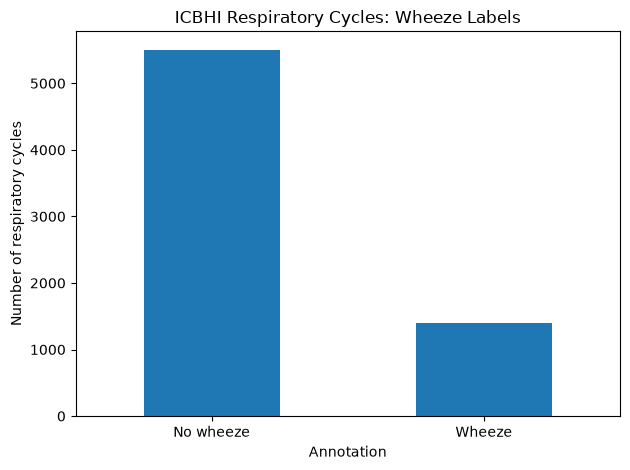

In [4]:
import matplotlib.pyplot as plt

label_counts = (
    df["wheezes"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

label_counts.index = ["No wheeze", "Wheeze"]

label_counts.plot(kind="bar")
plt.title("ICBHI Respiratory Cycles: Wheeze Labels")
plt.xlabel("Annotation")
plt.ylabel("Number of respiratory cycles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Cell 6 — Inspect wheeze-positive cycles

**Purpose:** Filter `df` to rows where `wheezes == 1` and display example recordings, patient IDs, time boundaries, and durations.

**Why this matters:** Before augmentation, listen to and visualize representative positive and negative cycles. Labels are inherited from the dataset annotations; synthetic examples should be clearly marked as synthetic and should never be treated as new clinical observations.


In [5]:
positive_cycles = df[df["wheezes"] == 1]

print("Wheeze-positive cycles:", len(positive_cycles))

display(
    positive_cycles[
        ["recording", "patient_id", "start", "end", "duration"]
    ].head(15)
)

Wheeze-positive cycles: 1392


,recording,patient_id,start,end,duration
36,103_2b2_Ar_mc_LittC2SE.wav,103,0.36400,3.25000,2.88600
38,103_2b2_Ar_mc_LittC2SE.wav,103,6.63600,11.17900,4.54300
39,103_2b2_Ar_mc_LittC2SE.wav,103,11.17900,14.25000,3.07100
40,103_2b2_Ar_mc_LittC2SE.wav,103,14.25000,16.99300,2.74300
48,104_1b1_Ar_sc_Litt3200.wav,104,0.00000,0.54469,0.54469
49,104_1b1_Ar_sc_Litt3200.wav,104,0.54469,2.96280,2.41811
50,104_1b1_Ar_sc_Litt3200.wav,104,2.96280,5.10850,2.14570
51,104_1b1_Ar_sc_Litt3200.wav,104,5.10850,7.21720,2.10870
52,104_1b1_Ar_sc_Litt3200.wav,104,7.21720,9.14420,1.92700
53,104_1b1_Ar_sc_Litt3200.wav,104,9.14420,10.67500,1.53080


## Cell 7 — Reserved continuation cell

This cell was empty in the uploaded notebook. The documented workflow below adds new cells for patient-level splitting, real-audio augmentation, and optional experimental synthetic wheeze overlays.


# Next phase — Prepare data augmentation safely

The following cells use the existing `df` table. **Run the notebook from the top, in order**, after confirming the dataset path is still available.

The main plan is:
1. Split by **patient ID** into training, validation, and test groups.
2. Augment only real wheeze-positive cycles from the training patients.
3. Optionally create a small, separately labeled set of artificial wheeze-like tonal overlays on real non-wheeze training backgrounds.
4. Save every generated WAV file and a CSV manifest so each sample is traceable.

**Scientific caution:** augmentation creates variants, not new independent patients. The artificial tones are simplified experiments, not real wheezes or medical evidence. Keep validation/test data real and untouched, and compare model results with and without synthetic data.


## Cell 8 — Check required audio libraries and inspect the data

This cell confirms that the packages used for WAV loading/saving are available and checks the required columns. If `soundfile` is missing, install it in your active `crobemlmine` Conda environment with `conda install -c conda-forge pysoundfile`.


In [6]:
import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

required_columns = {
    "recording", "patient_id", "start", "end", "duration",
    "crackles", "wheezes", "audio_path"
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"df is missing required columns: {sorted(missing_columns)}")

print("soundfile version:", sf.__version__)
print("Rows in df:", len(df))
print("Patients:", df["patient_id"].nunique())
print("Wheeze-positive:", int((df["wheezes"] == 1).sum()))
print("Wheeze-negative:", int((df["wheezes"] == 0).sum()))
print("Example sample rate / channels:")
example_audio, example_sr = sf.read(df.iloc[0]["audio_path"])
print(f"{example_sr} Hz, shape={example_audio.shape}")


soundfile version: 0.14.0
Rows in df: 6898
Patients: 126
Wheeze-positive: 1392
Wheeze-negative: 5506
Example sample rate / channels:
44100 Hz, shape=(882000,)


## Cell 9 — Split patients before generating any augmented samples

**Why first?** If an augmented copy of a patient's recording appears in training while another segment from that same patient appears in testing, the test score can be misleading. This split assigns each patient to exactly one group.

The split is approximately 70% training patients, 15% validation patients, and 15% test patients. All validation and test audio remains original and unaugmented.


In [7]:
from sklearn.model_selection import train_test_split

SEED = 42
patient_ids = np.array(sorted(df["patient_id"].astype(str).unique()))

train_patients, temp_patients = train_test_split(
    patient_ids, test_size=0.30, random_state=SEED
)
val_patients, test_patients = train_test_split(
    temp_patients, test_size=0.50, random_state=SEED
)

# Convert to strings for consistent matching with the metadata table.
df["patient_id"] = df["patient_id"].astype(str)
train_df = df[df["patient_id"].isin(train_patients)].copy()
val_df = df[df["patient_id"].isin(val_patients)].copy()
test_df = df[df["patient_id"].isin(test_patients)].copy()

assert set(train_patients).isdisjoint(set(val_patients))
assert set(train_patients).isdisjoint(set(test_patients))
assert set(val_patients).isdisjoint(set(test_patients))

print(f"Training patients: {len(train_patients)} | cycles: {len(train_df)}")
print(f"Validation patients: {len(val_patients)} | cycles: {len(val_df)}")
print(f"Test patients: {len(test_patients)} | cycles: {len(test_df)}")
print("\nWheeze counts by split:")
display(pd.DataFrame({
    "train": train_df["wheezes"].value_counts().reindex([0, 1], fill_value=0),
    "validation": val_df["wheezes"].value_counts().reindex([0, 1], fill_value=0),
    "test": test_df["wheezes"].value_counts().reindex([0, 1], fill_value=0),
}, index=[0, 1]).rename(index={0: "No wheeze", 1: "Wheeze"}))


Training patients: 88 | cycles: 4915
Validation patients: 19 | cycles: 1165
Test patients: 19 | cycles: 818

Wheeze counts by split:


,train,validation,test
No wheeze,3920,998,588
Wheeze,995,167,230


## Cell 10 — Extract and augment real wheeze-positive training cycles

This cell extracts the annotated time interval from each original WAV file and makes two conservative variants:
- **Gain change:** modest volume variation.
- **Low-level noise:** adds quiet random noise to improve robustness to recording conditions.
- **Small time shift:** moves the waveform slightly while keeping the same duration.

These transformations preserve the original wheeze label, but they do not add new independent clinical examples. Only positive cycles from training patients are augmented. The original validation/test recordings are never changed.

Generated files are saved under `~/datasets/ICBHI_augmented/real_wheeze_augmentations/`, with a CSV manifest containing the original file, patient, label, sample rate, and augmentation type.


In [8]:
from pathlib import Path

OUTPUT_ROOT = Path.home() / "datasets" / "ICBHI_augmented"
REAL_AUG_DIR = OUTPUT_ROOT / "real_wheeze_augmentations"
REAL_AUG_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEED)

def extract_cycle(row):
    audio, sr = sf.read(row["audio_path"], dtype="float32")
    if audio.ndim == 2:
        audio = audio.mean(axis=1)  # convert stereo to mono
    start_sample = max(0, int(round(float(row["start"]) * sr)))
    end_sample = min(len(audio), int(round(float(row["end"]) * sr)))
    cycle = audio[start_sample:end_sample]
    if len(cycle) < int(0.10 * sr):
        return None, sr
    # Remove DC offset; avoid normalizing every cycle to the same loudness.
    cycle = cycle - np.mean(cycle)
    return cycle.astype(np.float32), sr

def shift_without_wrap(audio, shift_samples):
    shifted = np.zeros_like(audio)
    if shift_samples > 0:
        shifted[shift_samples:] = audio[:-shift_samples]
    elif shift_samples < 0:
        shifted[:shift_samples] = audio[-shift_samples:]
    else:
        shifted[:] = audio
    return shifted

def augment_real_cycle(audio, sr, rng):
    # Conservative gain adjustment.
    gain = float(rng.uniform(0.75, 1.25))
    out = audio * gain

    # Low-level noise based on the cycle's RMS. Keep it subtle.
    rms = float(np.sqrt(np.mean(out ** 2) + 1e-12))
    noise_level = float(rng.uniform(0.001, 0.015)) * max(rms, 1e-4)
    out = out + rng.normal(0.0, noise_level, size=out.shape).astype(np.float32)

    # Shift by at most 5% of the segment; no circular wraparound.
    max_shift = max(1, int(0.05 * len(out)))
    shift = int(rng.integers(-max_shift, max_shift + 1))
    out = shift_without_wrap(out, shift)

    # Prevent clipping while preserving relative waveform shape.
    peak = float(np.max(np.abs(out))) if len(out) else 0.0
    if peak > 0.99:
        out = out * (0.99 / peak)
    return out.astype(np.float32), gain, noise_level, shift

manifest_rows = []
positive_train = train_df[train_df["wheezes"] == 1].reset_index(drop=True)
AUGMENTATIONS_PER_CYCLE = 2

for row_idx, row in positive_train.iterrows():
    cycle, sr = extract_cycle(row)
    if cycle is None:
        continue

    for aug_idx in range(AUGMENTATIONS_PER_CYCLE):
        augmented, gain, noise_level, shift = augment_real_cycle(cycle, sr, rng)
        start_tag = f"{float(row['start']):.3f}".replace(".", "p")
        out_name = (
            f"patient{row['patient_id']}_"
            f"{Path(row['recording']).stem}_cycle{start_tag}_"
            f"realaug{aug_idx + 1}.wav"
        )
        out_path = REAL_AUG_DIR / out_name
        sf.write(out_path, augmented, sr, subtype="PCM_16")

        manifest_rows.append({
            "generated_path": str(out_path),
            "source_recording": row["recording"],
            "patient_id": row["patient_id"],
            "start_seconds": float(row["start"]),
            "end_seconds": float(row["end"]),
            "label_wheeze": 1,
            "sample_rate_hz": int(sr),
            "generation_type": "real_cycle_augmentation",
            "augmentation_index": aug_idx + 1,
            "gain": gain,
            "noise_level": noise_level,
            "shift_samples": shift,
            "split": "train"
        })

real_aug_manifest = pd.DataFrame(manifest_rows)
real_manifest_path = OUTPUT_ROOT / "real_wheeze_augmentation_manifest.csv"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
real_aug_manifest.to_csv(real_manifest_path, index=False)

print("Source positive training cycles:", len(positive_train))
print("Augmented WAV files saved:", len(real_aug_manifest))
print("Audio folder:", REAL_AUG_DIR)
print("Manifest saved:", real_manifest_path)
display(real_aug_manifest.head())


Source positive training cycles: 995
Augmented WAV files saved: 1990
Audio folder: /home/vinsam/datasets/ICBHI_augmented/real_wheeze_augmentations
Manifest saved: /home/vinsam/datasets/ICBHI_augmented/real_wheeze_augmentation_manifest.csv


,generated_path,source_recording,patient_id,start_seconds,end_seconds,label_wheeze,sample_rate_hz,generation_type,augmentation_index,gain,noise_level,shift_samples,split
0,/home/vinsam/datasets/ICBHI_augmented/real_whe...,103_2b2_Ar_mc_LittC2SE.wav,103,0.364,3.250,1,44100,real_cycle_augmentation,1,1.136978,0.002203,-873,train
1,/home/vinsam/datasets/ICBHI_augmented/real_whe...,103_2b2_Ar_mc_LittC2SE.wav,103,0.364,3.250,1,44100,real_cycle_augmentation,2,1.139691,0.003509,-6252,train
2,/home/vinsam/datasets/ICBHI_augmented/real_whe...,103_2b2_Ar_mc_LittC2SE.wav,103,6.636,11.179,1,44100,real_cycle_augmentation,1,1.175237,0.003737,8762,train
3,/home/vinsam/datasets/ICBHI_augmented/real_whe...,103_2b2_Ar_mc_LittC2SE.wav,103,6.636,11.179,1,44100,real_cycle_augmentation,2,0.808313,0.001723,3471,train
4,/home/vinsam/datasets/ICBHI_augmented/real_whe...,103_2b2_Ar_mc_LittC2SE.wav,103,11.179,14.250,1,44100,real_cycle_augmentation,1,1.031024,0.002105,2643,train


## Cell 11 — Optional experiment: add a synthetic wheeze-like tone to real negative backgrounds

This is an **experimental synthetic-data method**, not a validated wheeze simulator. It generates a short frequency-sweeping tonal signal with harmonics and a smooth envelope, then mixes it quietly into a real wheeze-negative training cycle. The resulting example is labeled `1` because the artificial tone was inserted by construction—not because a clinician confirmed it is a wheeze.

Use only a limited sample for experiments. A classifier may learn the artificial tone rather than real wheezing, so compare models trained with and without these examples and evaluate exclusively on untouched real patient recordings. Do not use these synthetic samples to make clinical severity claims.


In [9]:
from scipy.signal import chirp

SYNTH_DIR = OUTPUT_ROOT / "experimental_synthetic_overlays"
SYNTH_DIR.mkdir(parents=True, exist_ok=True)

def make_wheeze_like_tone(n_samples, sr, rng):
    # Simplified tonal sweep. This is not a physiological model of all wheezes.
    duration = n_samples / sr
    t = np.arange(n_samples, dtype=np.float32) / sr
    f0 = float(rng.uniform(350, 700))
    f1 = float(rng.uniform(700, min(1600, sr * 0.40)))
    tone = chirp(t, f0=f0, f1=f1, t1=max(duration, 1e-3), method="linear").astype(np.float32)

    # Add a quieter second harmonic when it fits below Nyquist.
    if 2 * f1 < sr * 0.48:
        tone += 0.25 * np.sin(2 * np.pi * (f0 + f1) * 0.5 * 2 * t).astype(np.float32)

    # Smooth onset/offset envelope; random placement inside the cycle.
    envelope = np.ones(n_samples, dtype=np.float32)
    fade = max(1, int(0.08 * sr))
    fade = min(fade, max(1, n_samples // 2))
    envelope[:fade] = np.linspace(0, 1, fade, dtype=np.float32)
    envelope[-fade:] = np.linspace(1, 0, fade, dtype=np.float32)
    tone *= envelope
    return tone

negative_train = train_df[train_df["wheezes"] == 0].reset_index(drop=True)
MAX_SYNTHETIC_OVERLAYS = min(300, len(negative_train))
selected_indices = rng.choice(
    len(negative_train), size=MAX_SYNTHETIC_OVERLAYS, replace=False
) if MAX_SYNTHETIC_OVERLAYS else []

synthetic_rows = []

for synthetic_idx, source_idx in enumerate(selected_indices, start=1):
    row = negative_train.iloc[int(source_idx)]
    background, sr = extract_cycle(row)
    if background is None:
        continue

    tone = make_wheeze_like_tone(len(background), sr, rng)
    bg_rms = float(np.sqrt(np.mean(background ** 2) + 1e-12))
    tone_rms = float(np.sqrt(np.mean(tone ** 2) + 1e-12))
    # Quiet randomized overlay; avoid overwhelming the respiratory background.
    target_ratio = float(rng.uniform(0.05, 0.18))
    tone = tone * (target_ratio * max(bg_rms, 1e-4) / max(tone_rms, 1e-8))
    mixed = background + tone

    peak = float(np.max(np.abs(mixed))) if len(mixed) else 0.0
    if peak > 0.99:
        mixed = mixed * (0.99 / peak)

    out_path = SYNTH_DIR / f"synthetic_overlay_{synthetic_idx:04d}.wav"
    sf.write(out_path, mixed.astype(np.float32), sr, subtype="PCM_16")

    synthetic_rows.append({
        "generated_path": str(out_path),
        "source_recording": row["recording"],
        "patient_id": row["patient_id"],
        "start_seconds": float(row["start"]),
        "end_seconds": float(row["end"]),
        "label_wheeze": 1,
        "sample_rate_hz": int(sr),
        "generation_type": "experimental_synthetic_tonal_overlay",
        "split": "train_only",
        "synthetic_tone_rms_ratio": target_ratio,
        "clinical_validation": "not_validated"
    })

synthetic_manifest = pd.DataFrame(synthetic_rows)
synthetic_manifest_path = OUTPUT_ROOT / "experimental_synthetic_overlay_manifest.csv"
synthetic_manifest.to_csv(synthetic_manifest_path, index=False)

print("Experimental synthetic overlays saved:", len(synthetic_manifest))
print("Audio folder:", SYNTH_DIR)
print("Manifest saved:", synthetic_manifest_path)
display(synthetic_manifest.head())


Experimental synthetic overlays saved: 300
Audio folder: /home/vinsam/datasets/ICBHI_augmented/experimental_synthetic_overlays
Manifest saved: /home/vinsam/datasets/ICBHI_augmented/experimental_synthetic_overlay_manifest.csv


,generated_path,source_recording,patient_id,start_seconds,end_seconds,label_wheeze,sample_rate_hz,generation_type,split,synthetic_tone_rms_ratio,clinical_validation
0,/home/vinsam/datasets/ICBHI_augmented/experime...,184_1b1_Ar_sc_Meditron.wav,184,12.236,14.850,1,44100,experimental_synthetic_tonal_overlay,train_only,0.090095,not_validated
1,/home/vinsam/datasets/ICBHI_augmented/experime...,135_2b1_Tc_mc_LittC2SE.wav,135,15.707,18.007,1,44100,experimental_synthetic_tonal_overlay,train_only,0.054708,not_validated
2,/home/vinsam/datasets/ICBHI_augmented/experime...,207_3b2_Lr_mc_AKGC417L.wav,207,13.815,16.202,1,44100,experimental_synthetic_tonal_overlay,train_only,0.102325,not_validated
3,/home/vinsam/datasets/ICBHI_augmented/experime...,130_2b3_Tc_mc_AKGC417L.wav,130,10.744,12.958,1,44100,experimental_synthetic_tonal_overlay,train_only,0.118444,not_validated
4,/home/vinsam/datasets/ICBHI_augmented/experime...,163_8b3_Lr_mc_AKGC417L.wav,163,3.765,6.794,1,44100,experimental_synthetic_tonal_overlay,train_only,0.157855,not_validated


## Cell 12 — Verify saved files and export split metadata

This final check confirms that generated WAV files exist and that each manifest records its generation method. It also saves the original patient-level train/validation/test cycle assignments so you can reproduce the experiment.

Keep the manifests with the dataset. Do not merge synthetic examples into validation or test sets.


In [10]:
# Verify the generated manifests and a few WAV files.
if not real_aug_manifest.empty:
    missing_real = sum(not Path(p).exists() for p in real_aug_manifest["generated_path"])
else:
    missing_real = 0

if not synthetic_manifest.empty:
    missing_synthetic = sum(not Path(p).exists() for p in synthetic_manifest["generated_path"])
else:
    missing_synthetic = 0

split_table = df[["recording", "patient_id", "start", "end", "wheezes", "crackles"]].copy()
split_table["split"] = np.select(
    [
        split_table["patient_id"].isin(train_patients),
        split_table["patient_id"].isin(val_patients),
        split_table["patient_id"].isin(test_patienbts),
    ],
    ["train", "validation", "test"],
    default="unassigned"
)
split_path = OUTPUT_ROOT / "original_cycle_patient_split.csv"
split_table.to_csv(split_path, index=False)

print("Missing real-augmentation files:", missing_real)
print("Missing synthetic-overlay files:", missing_synthetic)
print("Original cycle split saved:", split_path)
print("Output root:", OUTPUT_ROOT)
print("\nNext: inspect/listen to examples, train a baseline on real data, then compare against training with real-audio augmentation and (separately) synthetic overlays.")


Missing real-augmentation files: 0
Missing synthetic-overlay files: 0
Original cycle split saved: /home/vinsam/datasets/ICBHI_augmented/original_cycle_patient_split.csv
Output root: /home/vinsam/datasets/ICBHI_augmented

Next: inspect/listen to examples, train a baseline on real data, then compare against training with real-audio augmentation and (separately) synthetic overlays.


Searches the ICBHI directory for a recording with a wheeze-positive annotation, extracts that respiratory cycle, creates a mildly augmented version, and plots both.
The spectrogram uses the short-time Fourier transform to show how frequency content changes over time. 
How to interpret the results
Look for these features in the bottom row:
- Preserved tonal structures: horizontal or slightly varying narrow frequency bands associated with the wheeze should remain visible after augmentation.
- Excessive broadband energy: noise may appear as a diffuse background across many frequencies.
- Clipping or distortion: unexpected changes in the waveform peaks may indicate that the audio needs further inspection.
Remember that wheezes do not always appear as perfectly continuous horizontal lines. Real respiratory sounds vary, and the spectrogram alone cannot establish whether a sound is clinically a wheeze.
Try different noise levels
Change NOISE_LEVEL at the top of the cell and run it again:

Dataset directory: /home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database

Recording: 103_2b2_Ar_mc_LittC2SE.wav
Sample rate: 44100 Hz
Wheeze cycle: 0.364–3.250 seconds
Cycle duration: 2.886 seconds
Original RMS:  0.271152
Augmented RMS: 0.270881
Noise level:   0.00% of original RMS


/tmp/ipykernel_17104/1063195864.py:200: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


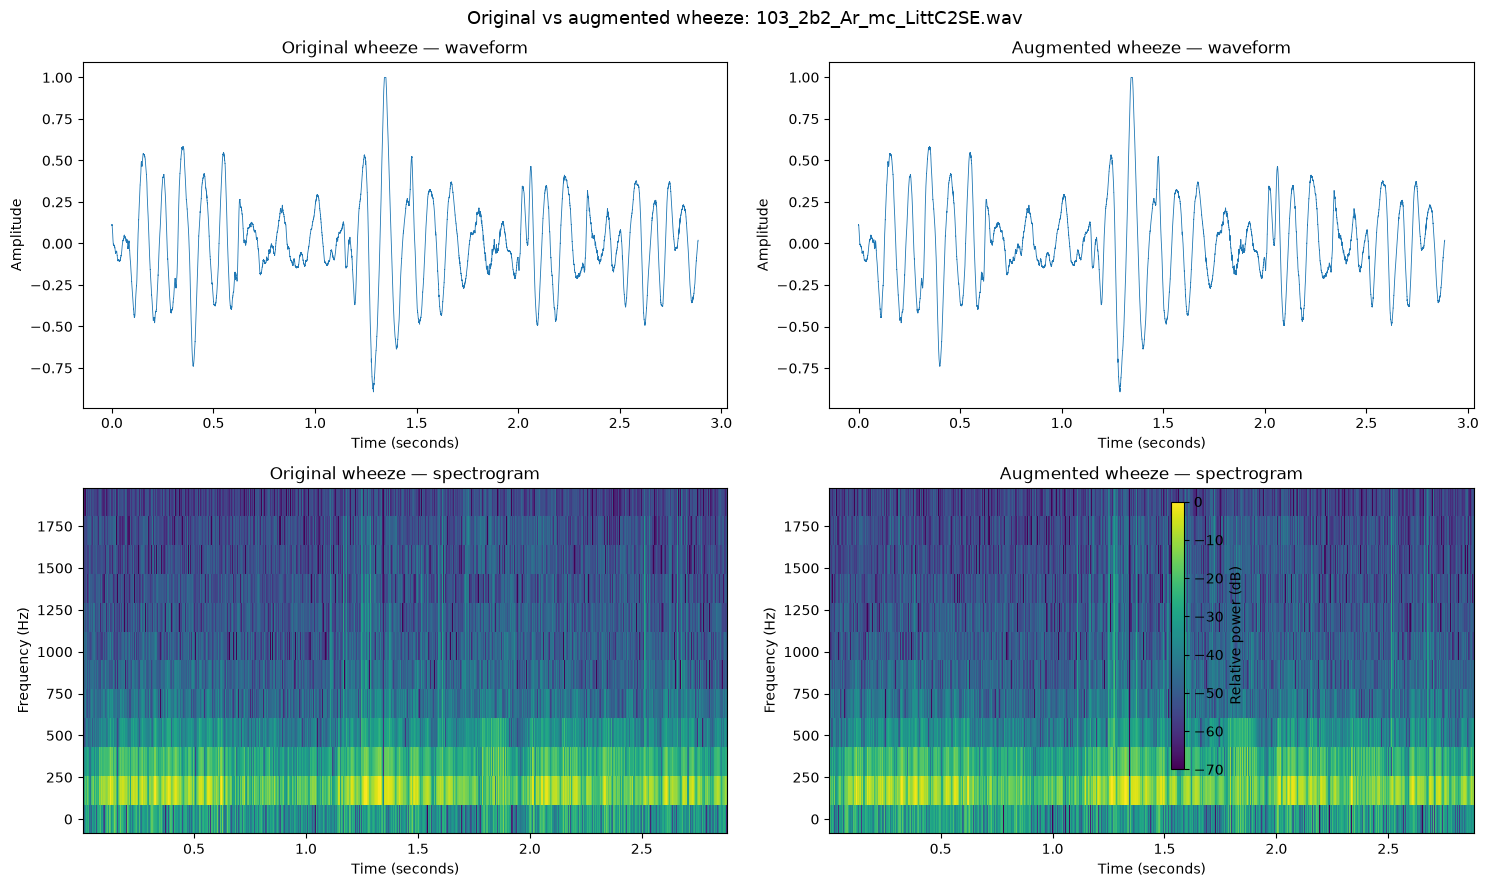

Listen to the ORIGINAL cycle:


Listen to the AUGMENTED cycle:


In [14]:

from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# -------------------------------------------------------
# 1. CONFIGURATION
# -------------------------------------------------------
DATA_DIR = Path(
    "/home/vinsam/.cache/kagglehub/datasets/"
    "nimalanparameshwaran/"
    "icbhi-2017-challenge-respiratory-sound-database/"
    "versions/1/ICBHI_final_database"
)

RANDOM_SEED = 42
NOISE_LEVEL = 0.000  # Noise RMS = 0.5% of signal RMS
GAIN = 3.1          # Change to 0.9 or 1.1 to test gain augmentation
MAX_FREQUENCY = 2000 # Respiratory frequency range to display

rng = np.random.default_rng(RANDOM_SEED)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

print("Dataset directory:", DATA_DIR)


# -------------------------------------------------------
# 2. FIND A CYCLE ANNOTATED AS WHEEZE-POSITIVE
# -------------------------------------------------------
wav_files = sorted(DATA_DIR.glob("*.wav"))

selected = None

for wav_path in wav_files:
    annotation_path = wav_path.with_suffix(".txt")

    if not annotation_path.exists():
        continue

    try:
        annotations = np.loadtxt(annotation_path, ndmin=2)

        # ICBHI columns:
        # start, end, crackle, wheeze
        if annotations.shape[1] < 4:
            continue

        wheeze_rows = annotations[annotations[:, 3] == 1]

        if len(wheeze_rows) > 0:
            selected = (wav_path, wheeze_rows[0])
            break

    except (ValueError, OSError):
        continue

if selected is None:
    raise RuntimeError("No wheeze-positive annotated cycles found.")

wav_path, annotation = selected
start_sec, end_sec = annotation[:2]

audio, sr = sf.read(wav_path)

# Convert stereo to mono if necessary
if audio.ndim == 2:
    audio = audio.mean(axis=1)

start_sample = int(start_sec * sr)
end_sample = int(end_sec * sr)

original = audio[start_sample:end_sample].astype(np.float32)

if len(original) < 2:
    raise ValueError("Selected respiratory cycle is too short.")

print(f"\nRecording: {wav_path.name}")
print(f"Sample rate: {sr} Hz")
print(f"Wheeze cycle: {start_sec:.3f}–{end_sec:.3f} seconds")
print(f"Cycle duration: {len(original) / sr:.3f} seconds")


# -------------------------------------------------------
# 3. CREATE A MILDLY AUGMENTED VERSION
# -------------------------------------------------------
# Keep the original unchanged.
# Noise is scaled relative to the signal's RMS amplitude.

rms = np.sqrt(np.mean(original ** 2))

if rms < 1e-10:
    raise ValueError("Selected audio has almost zero amplitude.")

noise = rng.normal(
    loc=0.0,
    scale=rms * NOISE_LEVEL,
    size=len(original)
).astype(np.float32)

augmented = original * GAIN + noise  #creates an augmented version of your original wheezing audio by adjusting its volume and adding a small amount of random noise.

# Prevent clipping without aggressively normalizing the signal.
peak = np.max(np.abs(augmented))

if peak > 0.999:
    augmented = augmented * (0.999 / peak)

print(f"Original RMS:  {rms:.6f}")
print(f"Augmented RMS: {np.sqrt(np.mean(augmented ** 2)):.6f}")
print(f"Noise level:   {NOISE_LEVEL * 100:.2f}% of original RMS")


# -------------------------------------------------------
# 4. COMPUTE SPECTROGRAMS
# -------------------------------------------------------
def compute_spectrogram(x, sample_rate):
    nperseg = min(256, len(x))
    noverlap = min(nperseg - 1, int(nperseg * 0.75))

    frequencies, times, power = signal.spectrogram(
        x,
        fs=sample_rate,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        scaling="spectrum",
        mode="psd"
    )

    # Convert power to decibels, avoiding log(0).
    power_db = 10 * np.log10(power + 1e-12)

    # Express relative to this signal's maximum.
    power_db -= np.max(power_db)

    return frequencies, times, power_db


f_orig, t_orig, s_orig = compute_spectrogram(original, sr)
f_aug, t_aug, s_aug = compute_spectrogram(augmented, sr)

# Use a common display range for both spectrograms.
vmin, vmax = -70, 0

duration = len(original) / sr
time_axis = np.arange(len(original)) / sr

# -------------------------------------------------------
# 5. PLOT WAVEFORMS AND SPECTROGRAMS SIDE BY SIDE
# -------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Original waveform
axes[0, 0].plot(time_axis, original, linewidth=0.6)
axes[0, 0].set_title("Original wheeze — waveform")
axes[0, 0].set_xlabel("Time (seconds)")
axes[0, 0].set_ylabel("Amplitude")

# Augmented waveform
axes[0, 1].plot(time_axis, augmented, linewidth=0.6)
axes[0, 1].set_title("Augmented wheeze — waveform")
axes[0, 1].set_xlabel("Time (seconds)")
axes[0, 1].set_ylabel("Amplitude")

# Original spectrogram
mask_orig = f_orig <= min(MAX_FREQUENCY, sr / 2)
im1 = axes[1, 0].pcolormesh(
    t_orig, f_orig[mask_orig], s_orig[mask_orig],
    shading="auto", vmin=vmin, vmax=vmax
)
axes[1, 0].set_title("Original wheeze — spectrogram")
axes[1, 0].set_xlabel("Time (seconds)")
axes[1, 0].set_ylabel("Frequency (Hz)")

# Augmented spectrogram
mask_aug = f_aug <= min(MAX_FREQUENCY, sr / 2)
im2 = axes[1, 1].pcolormesh(
    t_aug, f_aug[mask_aug], s_aug[mask_aug],
    shading="auto", vmin=vmin, vmax=vmax
)
axes[1, 1].set_title("Augmented wheeze — spectrogram")
axes[1, 1].set_xlabel("Time (seconds)")
axes[1, 1].set_ylabel("Frequency (Hz)")

fig.colorbar(
    im2, ax=[axes[1, 0], axes[1, 1]],
    label="Relative power (dB)", shrink=0.85
)

fig.suptitle(
    f"Original vs augmented wheeze: {wav_path.name}",
    fontsize=13
)
plt.tight_layout()
plt.show()


# -------------------------------------------------------
# 6. LISTEN TO BOTH VERSIONS
# -------------------------------------------------------
print("Listen to the ORIGINAL cycle:")
display(Audio(original, rate=sr))

print("Listen to the AUGMENTED cycle:")
display(Audio(augmented, rate=sr))


Original RMS:       0.27115177
Added component RMS:0.56968983
Added/original:     210.100%
Estimated SNR:      3.38 dB


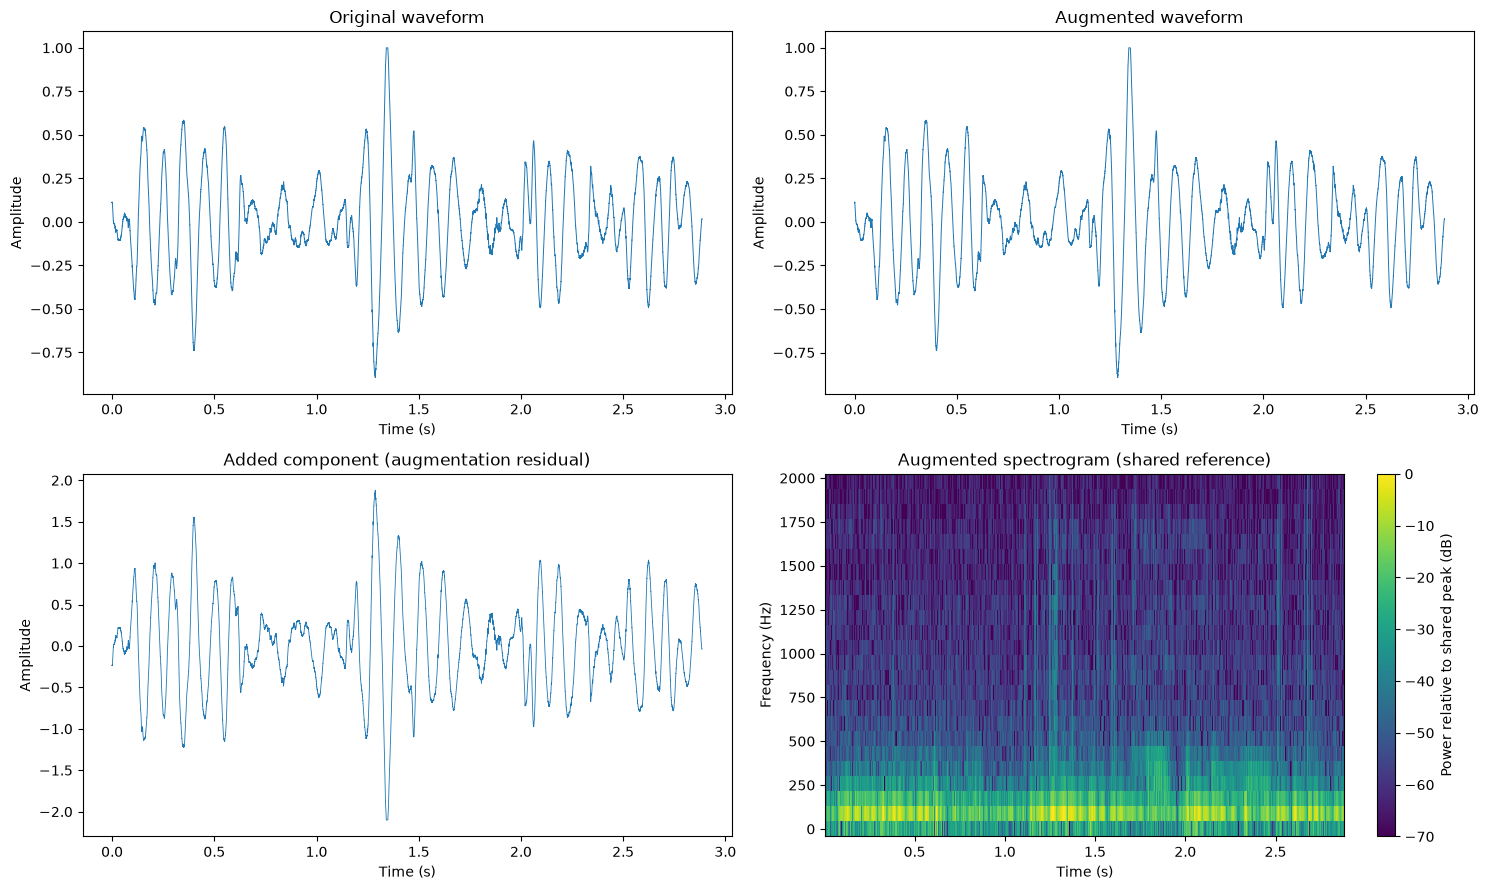

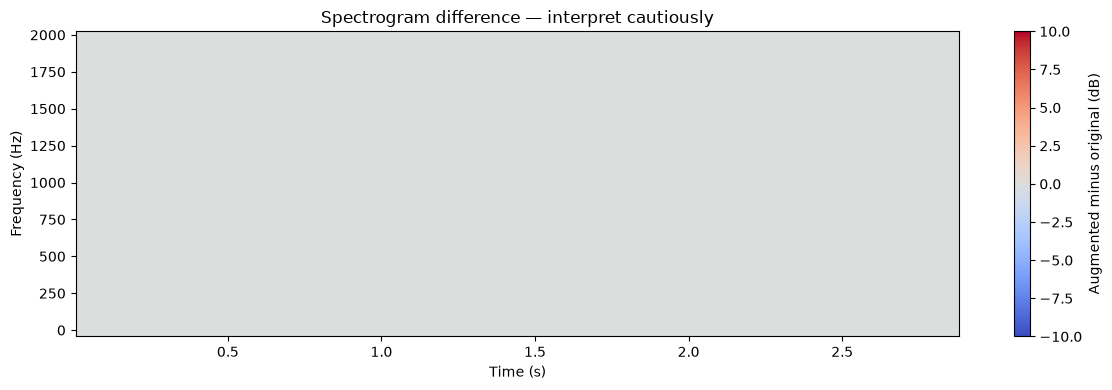

In [16]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# 1. Measure the actual change introduced by augmentation
original = np.asarray(original, dtype=np.float64)
augmented = np.asarray(augmented, dtype=np.float64)

# Remove the intended gain change before estimating the added component
residual = augmented - GAIN * original

original_rms = np.sqrt(np.mean(original ** 2))
residual_rms = np.sqrt(np.mean(residual ** 2))

noise_ratio = residual_rms / (original_rms + 1e-12)
estimated_snr_db = 20 * np.log10(
    (GAIN * original_rms + 1e-12) / (residual_rms + 1e-12)
)

print(f"Original RMS:       {original_rms:.8f}")
print(f"Added component RMS:{residual_rms:.8f}")
print(f"Added/original:     {noise_ratio * 100:.3f}%")
print(f"Estimated SNR:      {estimated_snr_db:.2f} dB")

# 2. Compute both spectrograms with the same settings
nperseg = min(512, len(original))
noverlap = min(int(nperseg * 0.75), nperseg - 1)

def get_power_spectrogram(x):
    f, t, power = signal.spectrogram(
        x,
        fs=sr,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        scaling="density",
        mode="psd"
    )
    return f, t, power

f1, t1, p_original = get_power_spectrogram(original)
f2, t2, p_augmented = get_power_spectrogram(augmented)

# Shared reference: do NOT normalize each spectrogram independently
common_reference = max(np.max(p_original), np.max(p_augmented), 1e-20)

original_db = 10 * np.log10(
    np.maximum(p_original, 1e-20) / common_reference
)
augmented_db = 10 * np.log10(
    np.maximum(p_augmented, 1e-20) / common_reference
)

# 3. Plot the original, augmented, and residual signals
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

time = np.arange(len(original)) / sr

axes[0, 0].plot(time, original, linewidth=0.7)
axes[0, 0].set_title("Original waveform")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Amplitude")

axes[0, 1].plot(time, augmented, linewidth=0.7)
axes[0, 1].set_title("Augmented waveform")
axes[0, 1].set_xlabel("Time (s)")
axes[0, 1].set_ylabel("Amplitude")

axes[1, 0].plot(time, residual, linewidth=0.6)
axes[1, 0].set_title("Added component (augmentation residual)")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Amplitude")

# Shared color scale for fair spectrogram comparison
vmin, vmax = -70, 0
frequency_limit = min(2000, sr / 2)
mask = f1 <= frequency_limit

im = axes[1, 1].pcolormesh(
    t1, f1[mask], augmented_db[mask],
    shading="auto", cmap="viridis",
    vmin=vmin, vmax=vmax
)
axes[1, 1].set_title("Augmented spectrogram (shared reference)")
axes[1, 1].set_xlabel("Time (s)")
axes[1, 1].set_ylabel("Frequency (Hz)")

fig.colorbar(im, ax=axes[1, 1], label="Power relative to shared peak (dB)")
plt.tight_layout()
plt.show()

# 4. Plot the spectrogram difference in dB
difference_db = augmented_db - original_db

plt.figure(figsize=(12, 4))
plt.pcolormesh(
    t1, f1[mask], difference_db[mask],
    shading="auto", cmap="coolwarm",
    vmin=-10, vmax=10
)
plt.colorbar(label="Augmented minus original (dB)")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram difference — interpret cautiously")
plt.tight_layout()
plt.show()
